In [1]:
%pip install pygad


   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


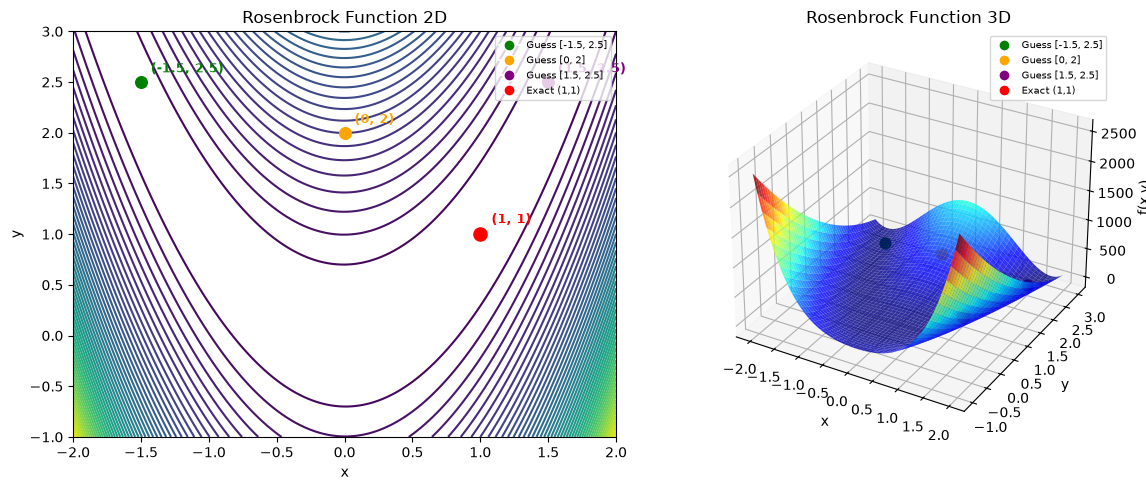

Initial guess [-1.5, 2.5], Result: [0.99999552 0.99999104], Value: 2.0064993034014284e-11, Success: True, Iterations: 36, Time: 0.0106 sec
Initial guess [0, 2], Result: [0.99999541 0.99999079], Value: 2.1138989539684907e-11, Success: True, Iterations: 23, Time: 0.0057 sec
Initial guess [1.5, 2.5], Result: [0.99999716 0.99999431], Value: 8.070353194467392e-12, Success: True, Iterations: 17, Time: 0.0044 sec
PyGAD initial guess [-1.5, 2.5], Solution: [0.96227617 0.92640727], Value: 0.0014417359581085402, iterations: 2000, Time: 0.7961 sec
PyGAD initial guess [0, 2], Solution: [0.97547018 0.9520843 ], Value: 0.0006311131440646799, iterations: 2000, Time: 0.8032 sec
PyGAD initial guess [1.5, 2.5], Solution: [0.97186    0.94629997], Value: 0.0011115922219376122, iterations: 2000, Time: 0.7175 sec


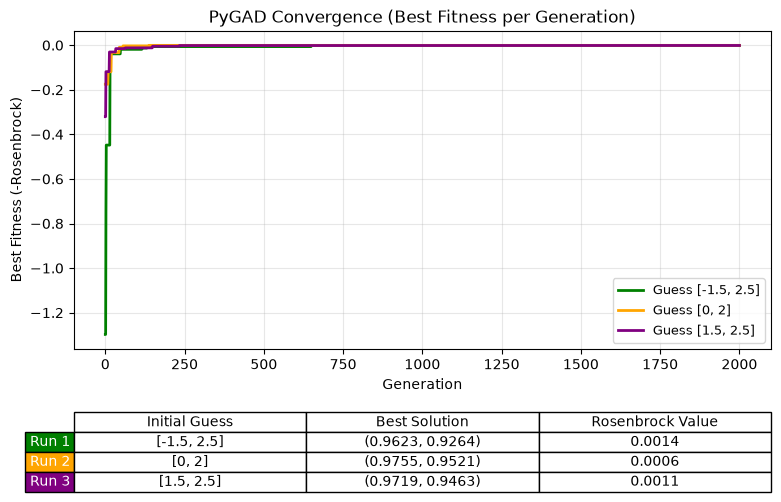

In [10]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad

def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# ---------------- 2D & 3D plots with markers ----------------
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

init_guesses = [
    [-1.5, 2.5],
    [0, 2],
    [1.5, 2.5]
]
exact_solution = [1, 1]
colors = ['green', 'orange', 'purple']   # one color per guess/run

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)
ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_xlim(-2, 2); ax1.set_ylim(-1, 3)

for g, c in zip(init_guesses, colors):
    ax1.scatter(g[0], g[1], color=c, s=70, zorder=5)
    ax1.annotate(f"({g[0]}, {g[1]})", (g[0], g[1]), xytext=(7, 7),
                 textcoords="offset points", color=c, fontsize=9, fontweight='bold')

ax1.scatter(*exact_solution, color='red', s=90, zorder=6)
ax1.annotate("(1, 1)", exact_solution, xytext=(8, 8),
             textcoords="offset points", color='red', fontsize=9, fontweight='bold')

handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8) for c in colors]
handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8))
ax1.legend(handles, [f"Guess {g}" for g in init_guesses] + ["Exact (1,1)"], loc="upper right", fontsize=7)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("f(x,y)")

for g, c in zip(init_guesses, colors):
    ax2.scatter(g[0], g[1], rosenbrock(g), color=c, s=60)
ax2.scatter(*exact_solution, rosenbrock(exact_solution), color='red', s=90)
ax2.legend(handles, [f"Guess {g}" for g in init_guesses] + ["Exact (1,1)"], loc="upper right", fontsize=7)

plt.tight_layout()
plt.show()

# ---------------- Scipy Optimization ----------------
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    elapsed_time = time.perf_counter() - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# ---------------- PyGAD Optimization (combined plot) ----------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)

fig, ax = plt.subplots(figsize=(9, 6))
best_solutions, table_rows = [], []

for guess, c in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000, sol_per_pop=20, num_genes=2,
                            num_parents_mating=8, fitness_func=fitness_func,
                            init_range_low=-2, init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    elapsed_time = time.perf_counter() - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    ax.plot(ga_instance.best_solutions_fitness, color=c, linewidth=2, label=f"Guess {guess}")
    best_solutions.append(solution)
    table_rows.append([str(guess), f"({solution[0]:.4f}, {solution[1]:.4f})", f"{rosenbrock(solution):.4f}"])

ax.set_title("PyGAD Convergence (Best Fitness per Generation)")
ax.set_xlabel("Generation"); ax.set_ylabel("Best Fitness (-Rosenbrock)")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

tbl = plt.table(cellText=table_rows, rowLabels=["Run 1", "Run 2", "Run 3"],
                 colLabels=["Initial Guess", "Best Solution", "Rosenbrock Value"],
                 cellLoc='center', loc='bottom', bbox=[0.0, -0.45, 1.0, 0.25])
for i, c in enumerate(colors):
    tbl[(i + 1, -1)].set_facecolor(c)
    tbl[(i + 1, -1)].get_text().set_color('white')

plt.subplots_adjust(bottom=0.35)
plt.show()

BFGS & PyGAD

BFGS is a smart, math-based method — it looks at the slope of the function and uses that to quickly figure out which direction to move, so it reaches the minimum point (1, 1) in just a few steps and very fast. PyGAD works completely differently — it doesn't look at slopes at all. Instead, it keeps a group of random guesses and slowly improves them over many rounds by mixing and randomly tweaking them, hoping to stumble onto the best answer. Since it runs 2000 rounds with 20 guesses each round, it has to check the function around 40,000 times, which is why PyGAD takes much longer to run than BFGS, even though both eventually get close to the right answer.

ROSENBROCK

In this code, the Rosenbrock function is defined as f(x,y) = (1-x)² + 100*(y-x²)²
First, it's calculated over a grid of x and y values to draw the contour and 3D surface plots, so you can visually see the curved valley shape. 
Then, three starting points — (-1.5, 2.5), (0, 2), (1.5, 2.5) — are given to both BFGS and PyGAD, and each algorithm tries to find the x, y values that make this function as small as possible. 
BFGS uses the slope of the function to quickly move toward the minimum, while PyGAD tries many random combinations of x, y over generations and keeps the best ones.
At the end, both print how close they got to the true minimum (1, 1) and how long they took, so the code is basically using the Rosenbrock function as a common challenge to compare the two optimization approaches.

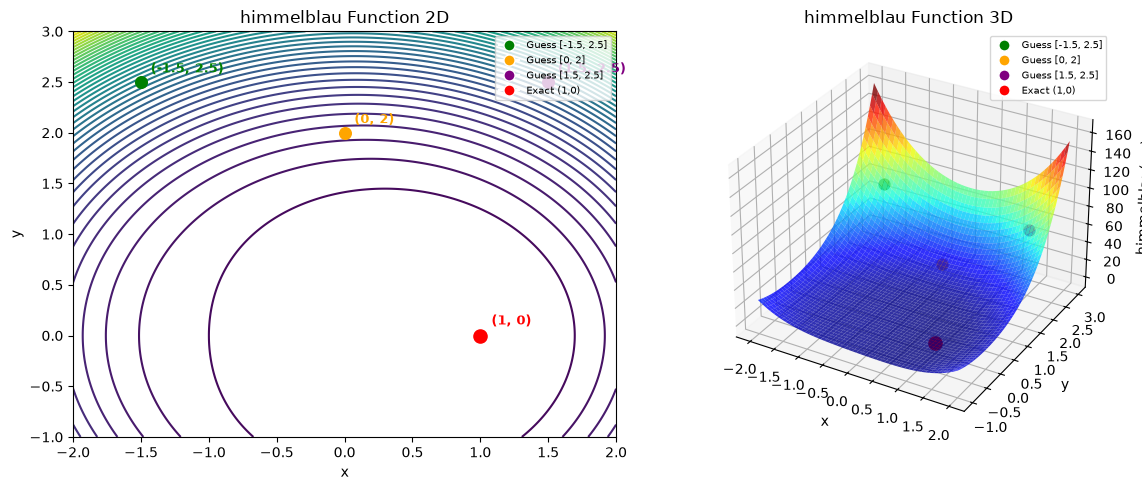

Initial guess [-1.5, 2.5], Result: [1.00000026e+00 1.29565146e-06], Value: 2.0287597165852328e-12, Success: True, Iterations: 15, Time: 0.0062 sec
Initial guess [0, 2], Result: [ 9.99999991e-01 -1.83677435e-08], Value: 7.107724692227636e-16, Success: True, Iterations: 11, Time: 0.0032 sec
Initial guess [1.5, 2.5], Result: [9.99999748e-01 1.43864660e-07], Value: 3.3788921010182345e-13, Success: True, Iterations: 13, Time: 0.0026 sec
PyGAD initial guess [-1.5, 2.5], Solution: [ 9.99105246e-01 -1.23043583e-04], Value: 4.01514666092352e-06, Iterations: 300, Time: 0.1869 sec
PyGAD initial guess [0, 2], Solution: [1.00169802 0.0013112 ], Value: 1.6166934178268908e-05, Iterations: 300, Time: 0.1675 sec
PyGAD initial guess [1.5, 2.5], Solution: [ 9.96890469e-01 -5.25001447e-04], Value: 4.849795149631722e-05, Iterations: 300, Time: 0.1681 sec


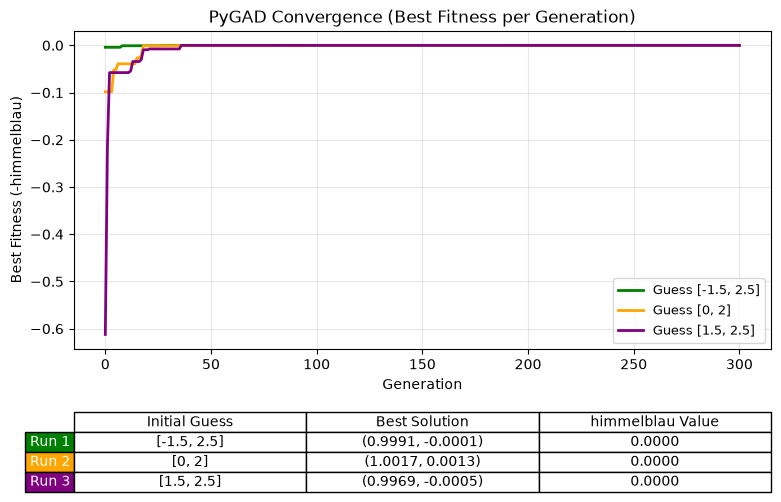

In [15]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad

def himmelblau(x):
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + x[1]**2

# ---------------- 2D & 3D plots with markers ----------------
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

init_guesses = [
    [-1.5, 2.5],
    [0, 2],
    [1.5, 2.5]
]
exact_solution = [1, 0]   # analytically derived minimum, f = 0
colors = ['green', 'orange', 'purple']   # one color per guess/run

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)
ax1.contour(X, Y, Z, levels=50)
ax1.set_title("himmelblau Function 2D")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_xlim(-2, 2)
ax1.set_ylim(-1, 3)

for g, c in zip(init_guesses, colors):
    ax1.scatter(g[0], g[1], color=c, s=70, zorder=5)
    ax1.annotate(f"({g[0]}, {g[1]})", (g[0], g[1]), xytext=(7, 7),
                 textcoords="offset points", color=c, fontsize=9, fontweight='bold')

ax1.scatter(*exact_solution, color='red', s=90, zorder=6)
ax1.annotate("(1, 0)", exact_solution, xytext=(8, 8),
             textcoords="offset points", color='red', fontsize=9, fontweight='bold')

handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=8) for c in colors]
handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8))
ax1.legend(handles, [f"Guess {g}" for g in init_guesses] + ["Exact (1,0)"], loc="upper right", fontsize=7)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("himmelblau Function 3D")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("himmelblau(x,y)")

for g, c in zip(init_guesses, colors):
    ax2.scatter(g[0], g[1], himmelblau(g), color=c, s=60)
ax2.scatter(*exact_solution, himmelblau(exact_solution), color='red', s=90)
ax2.legend(handles, [f"Guess {g}" for g in init_guesses] + ["Exact (1,0)"], loc="upper right", fontsize=7)

plt.tight_layout()
plt.show()

# ---------------- Scipy Optimization ----------------
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    elapsed_time = time.perf_counter() - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# ---------------- PyGAD Optimization (combined plot) ----------------
def fitness_func(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

fig, ax = plt.subplots(figsize=(9, 6))
table_rows = []

for guess, c in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300, sol_per_pop=30, num_genes=2,
                            num_parents_mating=12, fitness_func=fitness_func,
                            init_range_low=-2, init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    elapsed_time = time.perf_counter() - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, "
          f"Iterations: {iters}, Time: {elapsed_time:.4f} sec")

    ax.plot(ga_instance.best_solutions_fitness, color=c, linewidth=2, label=f"Guess {guess}")
    table_rows.append([str(guess), f"({solution[0]:.4f}, {solution[1]:.4f})", f"{himmelblau(solution):.4f}"])

ax.set_title("PyGAD Convergence (Best Fitness per Generation)")
ax.set_xlabel("Generation")
ax.set_ylabel("Best Fitness (-himmelblau)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

tbl = plt.table(cellText=table_rows, rowLabels=["Run 1", "Run 2", "Run 3"],
                 colLabels=["Initial Guess", "Best Solution", "himmelblau Value"],
                 cellLoc='center', loc='bottom', bbox=[0.0, -0.45, 1.0, 0.25])
for i, c in enumerate(colors):
    tbl[(i + 1, -1)].set_facecolor(c)
    tbl[(i + 1, -1)].get_text().set_color('white')

plt.subplots_adjust(bottom=0.35)
plt.show()

Himmelblau's function is a standard multi-modal test function for optimization algorithms, defined as (x²+y-11)² + (x+y²-7)². Unlike Rosenbrock, which has one single global minimum in a narrow curved valley, the true Himmelblau function has four separate global minima of equal value (0), scattered at different (x, y) points

Himmelblau(x) in this code is (x²+y²-1)² + (x-1)² + y². Both parts of the formula are squared terms, so they can never go negative — the function is smallest when both squared parts get as close to zero as possible at the same time. That happens exactly at x=1, y=0, where (1+0-1)²=0 and (1-1)²=0 and 0²=0, giving a total of 0 — the true minimum.

BFGS starts at a guess, checks the slope (gradient) of the function there, and repeatedly steps "downhill" in the direction that reduces the value fastest, until it settles at the bottom.
PyGAD starts with a random population of (x,y) guesses, computes each one's fitness (negative of the function value, since PyGAD maximizes), and evolves the population generation after generation — keeping better guesses, mixing them, and mutating them — until it converges near the same minimum.